# Module 2 — Advanced Regression

**Task:** regressione multipla del **BMI** (`Physical-BMI`) a partire dalle altre caratteristiche del dataset CMI
(misure fisiche, composizione corporea, fitness, attività fisica, sonno, uso di internet), con due approcci **non
lineari** visti a lezione (**Random Forest** e **Gradient Boosting / LightGBM**), confrontati con una baseline banale
e con un modello lineare di riferimento.

**Perché il BMI.** Nell'analisi esplorativa preliminare il BMI è il candidato con il miglior compromesso fra
segnale disponibile (R² ≈ 0.5 in CV anche senza peso e altezza), quota di valori imputati (7%, contro il 20% di
`BIA_Fat`) e legame con il tema del progetto (sedentarietà, attività fisica e uso di internet). `SDS_Total_T` e
`CGAS_Score` sono stati scartati perché non prevedibili (R² ≈ 0). **Peso e altezza sono esclusi** dalle feature
perché il BMI è calcolato da loro (703·peso/altezza², in libbre e pollici): tenerli sarebbe target leakage.

**Perché questi due modelli.** Il Gradient Boosting è l'unico argomento del corso per cui le slide trattano
esplicitamente la regressione (alberi di regressione allenati sui residui) ed è veloce nella versione LightGBM. La
Random Forest è stato il modello con la F1-macro più alta nella classificazione di `sii`: ritestarla sulla
regressione permette di verificare se il risultato si conferma su un altro task. I due modelli rappresentano le due
strategie di ensemble del corso: **bagging** (alberi indipendenti e profondi, media delle predizioni) e **boosting**
(alberi piccoli in sequenza, ognuno corregge i residui dei precedenti).

**Struttura del notebook**
1. Setup e versioni delle librerie
2. Caricamento dei dati, preprocessing e analisi del target
3. Funzioni di valutazione
4. Modelli di riferimento: Dummy, Linear Regression, Ridge
5. Random Forest: tuning, curva di validazione, numero di alberi (OOB)
6. LightGBM: tuning, effetto degli iperparametri, numero di alberi e learning rate
7. Confronto in cross-validation e robustezza (CV ripetuta 3×5)
8. Valutazione finale sul test set: metriche, predetto contro reale, residui, errore per fascia di BMI
9. Feature importance (MDI e permutation importance)
10. Regressione senza le righe con BMI imputato (BMI = 17.94) e confronto
11. Sintesi per il report

**Legenda.** Sotto ogni risultato c'è un commento con i numeri e la loro interpretazione; i blocchi **📌 Report**
indicano cosa portare nel report (tabelle, grafici, frasi chiave).

**Metriche:** MSE, MAE e R², le metriche di valutazione della regressione presentate nel corso (slide di regressione
di DM1; l'MSE è anche la loss delle reti neurali e il criterio di split degli alberi di regressione nelle slide di
DM2). Nelle tabelle si riporta anche l'RMSE (radice dell'MSE) solo come lettura aggiuntiva nella stessa unità del BMI.

**Tempo di esecuzione:** 10-14 minuti nei run di prova su una CPU con 2 core; con più core il tempo scende
(la parte più lenta è la griglia della Random Forest). L'ultima cella stampa il tempo reale.

> ⚠️ **Numeri provvisori.** I numeri nei commenti vengono da un run di prova (scikit-learn 1.7.2, lightgbm 4.7.0) e
> vanno sostituiti con quelli del run definitivo.

## 1. Setup

In [1]:
import time
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import sklearn
import lightgbm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_validate)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', message='X does not have valid feature names')

RANDOM_STATE = 42
T_START = time.time()

print('Python      ', sys.version.split()[0])
print('numpy       ', np.__version__)
print('pandas      ', pd.__version__)
print('matplotlib  ', matplotlib.__version__)
print('scikit-learn', sklearn.__version__)
print('lightgbm    ', lightgbm.__version__)

Python       3.12.0
numpy        2.3.3
pandas       2.3.3
matplotlib   3.10.6
scikit-learn 1.7.2
lightgbm     4.7.0


Le versioni coincidono con quelle dei notebook di classificazione (scikit-learn 1.7.2, lightgbm 4.7.0).
`RANDOM_STATE = 42` per split, cross-validation e modelli.

## 2. Caricamento dei dati, preprocessing e analisi del target

Convenzioni identiche ai notebook di classificazione, con le modifiche necessarie per la regressione:
- target `y = Physical-BMI`; da `X` si eliminano `id`, `sii` (target della classificazione) e le colonne da cui il
  BMI è calcolato (`Physical-Weight`, `Physical-Height`);
- split 80/20 **stratificato su `sii`** con `random_state=42`: le righe di test sono **le stesse** dei notebook di
  classificazione;
- stesso `ColumnTransformer` (StandardScaler sulle numeriche, OneHotEncoder con `drop='first'` sulle `*-Season`),
  sempre dentro una `Pipeline` con il modello;
- cross-validation `KFold(n_splits=5, shuffle=True, random_state=42)` (la stratificazione non si applica a un
  target continuo).

In [2]:
TARGET = 'Physical-BMI'
# BMI = 703 * peso / altezza^2 (libbre, pollici): peso e altezza sono gli ingredienti della formula -> target leakage
LEAKAGE_COLS = ['Physical-Weight', 'Physical-Height']

df = pd.read_csv('cmi_internet_final.csv')
y = df[TARGET]
X = df.drop(columns=['id', 'sii', TARGET] + LEAKAGE_COLS)

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]

# Stesso split dei notebook di classificazione: stratificato su sii -> stesse righe di test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=df['sii'], random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

n_feat = clone(preprocessor).fit(X_train).transform(X_train.iloc[:5]).shape[1]
print('Dataset:', df.shape)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print(f'Feature numeriche: {len(num_cols)}, categoriche: {len(cat_cols)}, dopo il preprocessing: {n_feat}')

Dataset: (8460, 50)
Train: (6768, 45)  Test: (1692, 45)
Feature numeriche: 35, categoriche: 10, dopo il preprocessing: 65


Training di 6768 righe e test di 1692 righe (come nella classificazione). Dopo il preprocessing restano
**65 feature** (68 della classificazione meno BMI, peso e altezza).

Statistiche del target (BMI):
        count   mean   std   min    25%    50%    75%   max
train  6768.0  19.47  4.48  9.69  16.57  17.94  21.32  47.7
test   1692.0  19.31  4.43  8.52  16.53  17.94  20.82  47.6

Asimmetria (skewness) sul training: 1.79

Valori più frequenti del BMI (intero dataset):
Physical-BMI
17.94    609
17.26     28
17.27     26
Righe con BMI = 17.94 (intero dataset): 609 (7.2%)
Righe con BMI = 17.94 (training): 498 (7.4%)
Righe con BMI = 17.94 (test): 111 (6.6%)

Prime 10 correlazioni con il BMI (training):
BIA-BIA_Fat                     0.606
BIA-BIA_FFM                     0.536
Physical-Waist_Circumference    0.497
Basic_Demos-Age                 0.414
BIA-BIA_DEE                     0.351
BIA-BIA_Frame_num               0.351
BIA-BIA_BMC                     0.310
Physical-Systolic_BP            0.281
FGC-FGC_GSD                     0.276
FGC-FGC_GSND                    0.249

Correlazione con le colonne escluse (training): {'Physical-Weight': np.float64(0.668

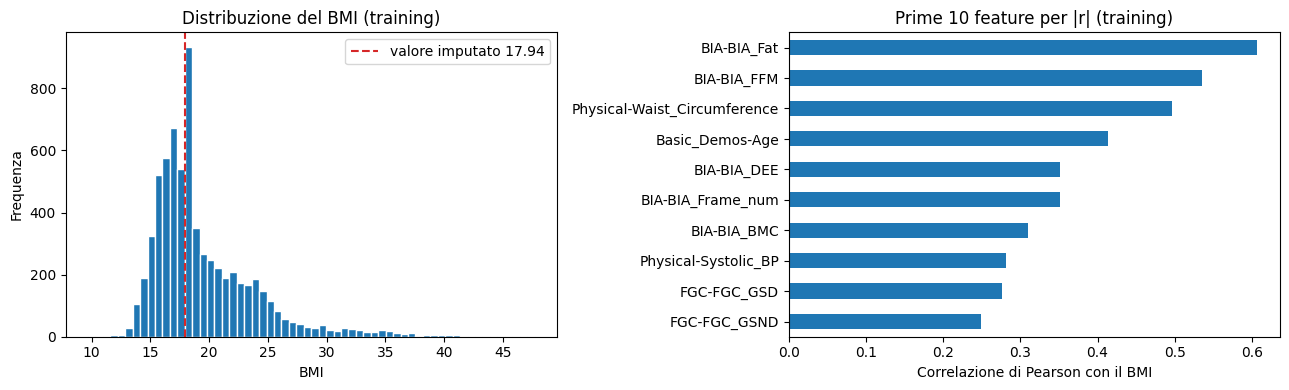

In [ ]:
IMPUTED_BMI = 17.94   # valore ripetuto in modo anomalo (imputazione del Modulo 0)

print('Statistiche del target (BMI):')
print(pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()}).round(2).T)
print(f'\nAsimmetria (skewness) sul training: {y_train.skew():.2f}')

top_vals = y.value_counts().head(3)
print('\nValori più frequenti del BMI (intero dataset):')
print(top_vals.to_string())
for name, yy in [('intero dataset', y), ('training', y_train), ('test', y_test)]:
    m = np.isclose(yy, IMPUTED_BMI)
    print(f'Righe con BMI = {IMPUTED_BMI} ({name}): {m.sum()} ({m.mean()*100:.1f}%)')

# Correlazioni (Pearson) delle feature numeriche con il BMI, calcolate solo sul training
corr = X_train[num_cols].corrwith(y_train).sort_values(key=np.abs, ascending=False)
print('\nPrime 10 correlazioni con il BMI (training):')
print(corr.head(10).round(3).to_string())
print('\nCorrelazione con le colonne escluse (training):',
      {c: round(df.loc[X_train.index, c].corr(y_train), 3) for c in LEAKAGE_COLS})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y_train, bins=60, color='tab:blue', edgecolor='white')
axes[0].axvline(IMPUTED_BMI, color='tab:red', ls='--', label=f'valore imputato {IMPUTED_BMI}')
axes[0].set_xlabel('BMI'); axes[0].set_ylabel('Frequenza'); axes[0].set_title('Distribuzione del BMI (training)')
axes[0].legend()
corr.head(10)[::-1].plot.barh(ax=axes[1], color='tab:blue')
axes[1].set_xlabel('Correlazione di Pearson con il BMI'); axes[1].set_title('Prime 10 feature per |r| (training)')
plt.tight_layout(); plt.show()

**Il target.** Il BMI ha media 19.5 e deviazione standard 4.5 sul training (statistiche quasi identiche sul test,
quindi lo split stratificato su `sii` non sbilancia il target). La distribuzione è **asimmetrica a destra**
(skewness 1.79): la maggior parte dei valori è fra 16.6 e 21.3 (quartili), con una coda fino a 47.7. I valori alti
sono pochi, quindi ci si aspetta che i modelli li sottostimino.

**Valore imputato.** Il valore **17.94 compare 609 volte** (7.2% del dataset; 498 righe nel training e 111 nel
test), mentre il secondo valore più frequente compare 28 volte: è la mediana usata nell'imputazione del Modulo 0 ed
è visibile come picco nell'istogramma. Per queste righe il "valore reale" del target non è una misura; l'effetto
viene analizzato nella sezione 9.

**Correlazioni.** Le feature più correlate con il BMI sono la composizione corporea (`BIA_Fat` 0.61, `BIA_FFM` 0.54),
la circonferenza vita (0.50) e l'età (0.41); fitness (punteggi FGC, al massimo 0.28) e le altre variabili sono
correlate debolmente. Peso (0.67) e altezza (0.48), esclusi, sarebbero state le feature più forti; anche se nel
dataset la relazione è indebolita da imputazione e campioni sintetici, il BMI resta per definizione una loro
funzione.

> 📌 **Report**
> - Motivazione della scelta del target (vedi intestazione) e delle colonne escluse per target leakage.
> - Istogramma del BMI con il picco a 17.94; frase: *"Il BMI ha distribuzione asimmetrica a destra (skewness 1.8);
>   il valore 17.94, usato per l'imputazione, compare nel 7% delle righe."*
> - Le correlazioni più forti sono con la composizione corporea e la circonferenza vita; quelle con fitness e
>   attività fisica sono deboli (coerente con la feature importance della classificazione).

## 3. Funzioni di valutazione

**Metriche** (quelle presentate nel corso per la regressione):
- **MSE** (errore quadratico medio), in unità di BMI al quadrato: penalizza molto gli errori grandi. È la **metrica
  usata per il tuning** (`neg_mean_squared_error`), perché coincide con la loss che i modelli minimizzano (criterio
  di split degli alberi di regressione e loss del gradient boosting) e perché interessa non sbagliare di molto i BMI
  estremi. Come riferimento, l'MSE del Dummy coincide con la varianza del BMI (≈ 20).
- **RMSE**: radice dell'MSE, riportata nelle tabelle solo come lettura aggiuntiva perché è nella stessa unità del BMI
  (punti di BMI); non viene usata per il tuning né per i confronti, che si basano sull'MSE.
- **MAE** (errore assoluto medio): nella stessa unità del BMI e più robusto agli errori grandi; si legge come "errore
  tipico" in punti di BMI.
- **R²** (coefficiente di determinazione): quota di varianza spiegata; 0 = predire sempre la media (Dummy),
  1 = predizione perfetta. È la metrica più comoda per confrontare risultati su dati con varianza diversa (sezione 10).

Le metriche si riportano sia sul **training** sia in **validation** (CV) per discutere l'overfitting.

In [4]:
SCORING = {'mse': 'neg_mean_squared_error',
           'rmse': 'neg_root_mean_squared_error',   # solo come metrica aggiuntiva (radice dell'MSE)
           'mae': 'neg_mean_absolute_error',
           'r2': 'r2'}


def make_pipe(model):
    """Pipeline preprocessing + modello (il preprocessor viene fittato solo sui dati di training di ogni fit)."""
    return Pipeline([('prep', clone(preprocessor)), ('model', model)])


def cv_scores(pipe, name, X_=None, y_=None, cv_=None):
    """Metriche medie (e dev. std) su training e validation della cross-validation."""
    X_ = X_train if X_ is None else X_
    y_ = y_train if y_ is None else y_
    cv_ = cv if cv_ is None else cv_
    res = cross_validate(pipe, X_, y_, cv=cv_, scoring=SCORING,
                         return_train_score=True, n_jobs=-1)
    row = {'modello': name}
    for m in SCORING:
        sign = 1 if m == 'r2' else -1
        row[f'{m}_train'] = sign * res[f'train_{m}'].mean()
        row[f'{m}_cv'] = sign * res[f'test_{m}'].mean()
        row[f'{m}_cv_std'] = res[f'test_{m}'].std()
    return row


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


def show_cv_table(rows):
    t = pd.DataFrame(rows).set_index('modello')
    cols = ['mse_train', 'mse_cv', 'mse_cv_std', 'rmse_train', 'rmse_cv', 'mae_train', 'mae_cv',
            'r2_train', 'r2_cv', 'r2_cv_std']
    return t[cols].round(3)


cv_rows = []   # raccoglie i risultati in CV di tutti i modelli finali

## 4. Modelli di riferimento: Dummy, Linear Regression, Ridge

- **Dummy (media)**: predice sempre la media del training; è il livello zero (R² = 0).
- **Linear Regression**: regressione lineare multipla con tutte le 65 feature; misura quanto segnale è catturabile
  con relazioni lineari.
- **Ridge**: regressione lineare con penalità L2; `alpha` scelto con una GridSearch su 13 valori da 0.01 a 10⁴ (scala
  logaritmica). È il riferimento lineare usato nel confronto finale.

La regressione logistica non si usa perché è un classificatore.

In [5]:
t0 = time.time()

# 1) Baseline banale: predice sempre la media del BMI del training
dummy = make_pipe(DummyRegressor(strategy='mean'))
cv_rows.append(cv_scores(dummy, 'Dummy (media)'))

# 2) Regressione lineare multipla (minimi quadrati, senza regolarizzazione)
linreg = make_pipe(LinearRegression())
cv_rows.append(cv_scores(linreg, 'Linear Regression'))

# 3) Ridge: regolarizzazione L2, alpha scelto con una griglia piccola (GridSearch) su scala logaritmica
ridge_search = GridSearchCV(make_pipe(Ridge()),
                            {'model__alpha': np.logspace(-2, 4, 13)},
                            cv=cv, scoring='neg_mean_squared_error', n_jobs=-1)
ridge_search.fit(X_train, y_train)
best_alpha = ridge_search.best_params_['model__alpha']
ridge = make_pipe(Ridge(alpha=best_alpha))
cv_rows.append(cv_scores(ridge, f'Ridge (alpha={best_alpha:g})'))

print(f'Ridge: alpha migliore = {best_alpha:g}, MSE CV = {-ridge_search.best_score_:.3f}')
print(f'Tempo: {time.time() - t0:.1f} s')
show_cv_table(cv_rows)

Ridge: alpha migliore = 316.228, MSE CV = 10.993
Tempo: 8.7 s


,mse_train,mse_cv,mse_cv_std,rmse_train,rmse_cv,mae_train,mae_cv,r2_train,r2_cv,r2_cv_std
modello,,,,,,,,,,
Dummy (media),20.077,20.080,0.740,4.481,4.480,3.312,3.313,0.000,-0.000,0.000
Linear Regression,10.707,11.034,0.625,3.272,3.320,2.147,2.175,0.467,0.449,0.038
Ridge (alpha=316.228),10.738,10.993,0.595,3.277,3.314,2.152,2.174,0.465,0.452,0.036


**Risultati in CV.** Il Dummy ha MSE 20.08 (la varianza del BMI) e MAE 3.31. Il modello lineare scende a **MSE 11.03 e
R² 0.449**; Ridge con `alpha = 316` dà quasi lo stesso risultato (MSE 10.99, R² 0.452). Training e validation sono
quasi uguali (differenza di MSE 0.26-0.33, R² 0.465 contro 0.452): **il modello lineare non va in overfitting**,
quindi la regolarizzazione aiuta pochissimo. Il limite del lineare è la mancanza di flessibilità (bias), non la
varianza: è lo spazio in cui possono guadagnare i modelli non lineari.

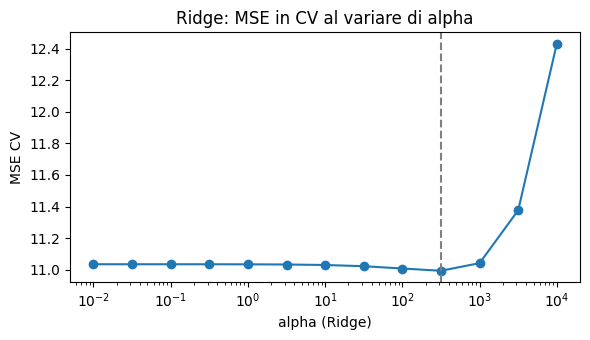

In [6]:
res = pd.DataFrame(ridge_search.cv_results_)
plt.figure(figsize=(6, 3.5))
plt.semilogx(res['param_model__alpha'].astype(float), -res['mean_test_score'], 'o-')
plt.axvline(best_alpha, color='gray', ls='--')
plt.xlabel('alpha (Ridge)'); plt.ylabel('MSE CV'); plt.title('Ridge: MSE in CV al variare di alpha')
plt.tight_layout(); plt.show()

L'MSE in CV è praticamente piatto per `alpha` piccoli, ha un minimo poco marcato a 316 e cresce per `alpha` ≥ 10³,
quando la penalità schiaccia i coefficienti. Il valore scelto non è sul bordo della griglia.

## 5. Random Forest

**Iperparametri provati e perché.** Nella Random Forest il numero di alberi non causa overfitting (lo si verifica
con la curva OOB), quindi il tuning riguarda la complessità di ogni albero e la diversità fra alberi:
- `max_features` ∈ {`sqrt` (≈ 8 feature), 0.33, 0.66, 1.0}: quante feature si considerano a ogni split. Valori
  piccoli rendono gli alberi più diversi (meno correlati); 1.0 è il bagging puro (default di scikit-learn per la
  regressione); 0.33 (p/3) è il valore classico consigliato per la regressione;
- `min_samples_leaf` ∈ {1, 5, 10, 20, 50}: dimensione minima delle foglie, cioè quanto è regolarizzato ogni albero
  (nella classificazione le foglie grandi erano la scelta migliore).

**Scelte per contenere i tempi.** Griglia completa di 20 configurazioni × 5 fold con 200 alberi; il numero finale
di alberi si sceglie dopo, con la curva OOB. È la parte più lenta del notebook.

In [7]:
t0 = time.time()

# Griglia completa (20 configurazioni x 5 fold): i due parametri che controllano la complessità della foresta
rf_grid = {
    'model__max_features': ['sqrt', 0.33, 0.66, 1.0],    # 1.0 = bagging puro (default sklearn per la regressione)
    'model__min_samples_leaf': [1, 5, 10, 20, 50],       # foglie più grandi = alberi più regolarizzati
}
# 200 alberi durante la ricerca (per contenere i tempi); il numero finale si sceglie con la curva OOB
rf_search = GridSearchCV(
    make_pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)),
    rf_grid, cv=cv, scoring='neg_mean_squared_error',
    return_train_score=True, n_jobs=-1)
rf_search.fit(X_train, y_train)

rf_res = pd.DataFrame(rf_search.cv_results_)
rf_res['mse_train'] = -rf_res['mean_train_score']
rf_res['mse_cv'] = -rf_res['mean_test_score']
rf_res['max_features'] = rf_res['param_model__max_features'].astype(str)
rf_res['min_samples_leaf'] = rf_res['param_model__min_samples_leaf'].astype(int)

print('Migliore configurazione:', rf_search.best_params_)
print(f'MSE CV migliore: {-rf_search.best_score_:.3f}')
print(f'Tempo: {time.time() - t0:.1f} s')
(rf_res.pivot(index='min_samples_leaf', columns='max_features', values='mse_cv').round(3))

Migliore configurazione: {'model__max_features': 0.66, 'model__min_samples_leaf': 5}
MSE CV migliore: 9.745
Tempo: 104.2 s


max_features,0.33,0.66,1.0,sqrt
min_samples_leaf,,,,
1,9.941,9.986,10.184,10.413
5,9.799,9.745,9.935,10.505
10,9.937,9.818,9.962,10.684
20,10.123,10.015,10.138,10.990
50,10.582,10.378,10.479,11.559


La configurazione migliore è **`max_features = 0.66`, `min_samples_leaf = 5`** con MSE CV **9.745** (Ridge: 10.99).
Le differenze nella griglia sono piccole (MSE fra 9.75 e 11.56): le configurazioni con `max_features` 0.33 e 0.66 e
foglie fra 1 e 10 sono tutte entro 0.25 dalla migliore (la dev. std fra i fold è ≈ 0.6), quindi la scelta è stabile.
`sqrt` è sempre la peggiore: con solo ≈ 8 feature per split spesso mancano le poche feature informative (BIA,
circonferenza vita, vedi sezione 9), quindi qui serve considerare più feature per split che nella classificazione
(dove era stato scelto `log2`).

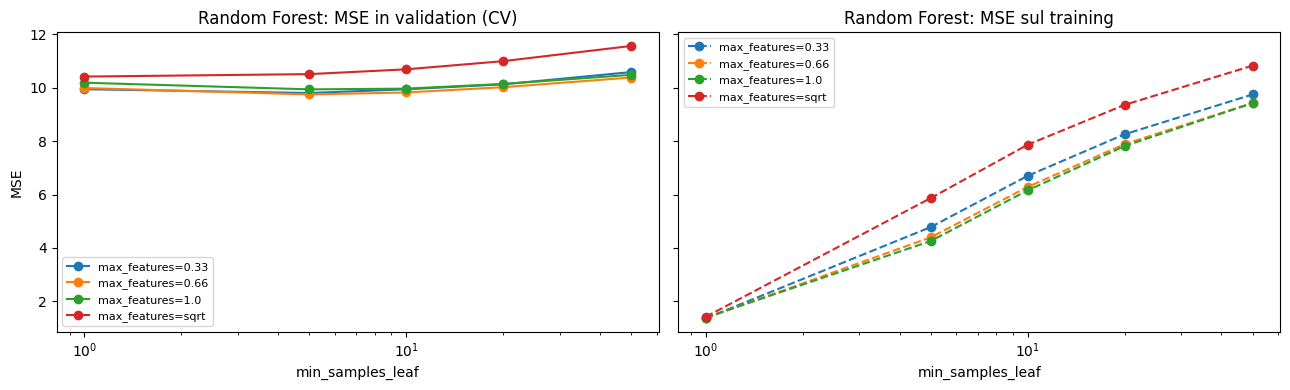

Configurazione migliore: MSE train 4.398  |  MSE CV 9.745


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for mf, g in rf_res.groupby('max_features'):
    g = g.sort_values('min_samples_leaf')
    axes[0].plot(g['min_samples_leaf'], g['mse_cv'], 'o-', label=f'max_features={mf}')
    axes[1].plot(g['min_samples_leaf'], g['mse_train'], 'o--', label=f'max_features={mf}')
axes[0].set_title('Random Forest: MSE in validation (CV)')
axes[1].set_title('Random Forest: MSE sul training')
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('min_samples_leaf'); ax.legend(fontsize=8)
axes[0].set_ylabel('MSE')
plt.tight_layout(); plt.show()

best_rf = rf_res.loc[rf_search.best_index_]
print(f"Configurazione migliore: MSE train {best_rf['mse_train']:.3f}  |  MSE CV {best_rf['mse_cv']:.3f}")

**Overfitting.** Per la configurazione migliore l'MSE è 4.40 sul training e 9.75 in validation: un divario grande,
tipico delle foreste (con `min_samples_leaf = 1` l'errore di training è ancora più basso). Come nella
classificazione, però, l'overfitting sul training è **poco dannoso**: con foglie più grandi l'errore di training sale
molto, mentre quello in validation resta quasi piatto e poi peggiora (MSE ≈ 10.4-10.6 con `min_samples_leaf = 50`).
Il minimo in validation è a foglie piccole-medie (5-10).

> 📌 **Report** — grafico dell'MSE di validation e di training al variare di `min_samples_leaf` per i 4 valori di
> `max_features`; frase: *"Nella Random Forest il divario training-validation è grande (MSE 4.4 contro 9.7), ma
> regolarizzare di più gli alberi non migliora la validazione."*

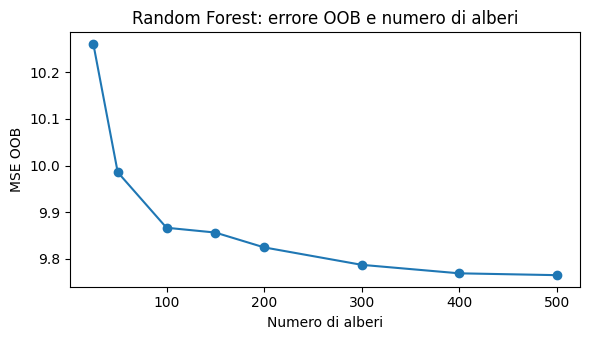

Tempo: 8.6 s


,n_estimators,mse_oob,r2_oob
0,25,10.2612,0.4889
1,50,9.9856,0.5026
2,100,9.8664,0.5086
3,150,9.8561,0.5091
4,200,9.8243,0.5107
5,300,9.7868,0.5125
6,400,9.7685,0.5134
7,500,9.7646,0.5136


In [9]:
t0 = time.time()

# Curva OOB: errore out-of-bag al crescere del numero di alberi (con i parametri migliori trovati sopra).
# warm_start=True aggiunge alberi a quelli già costruiti, quindi la curva costa come una sola foresta da 500 alberi.
prep_rf = clone(preprocessor).fit(X_train)
Xtr_rf = prep_rf.transform(X_train)
rf_best_params = {k.replace('model__', ''): v for k, v in rf_search.best_params_.items()}

rf_oob = RandomForestRegressor(oob_score=True, warm_start=True, random_state=RANDOM_STATE,
                               n_jobs=-1, **rf_best_params)
oob_rows = []
for n in [25, 50, 100, 150, 200, 300, 400, 500]:
    rf_oob.set_params(n_estimators=n)
    rf_oob.fit(Xtr_rf, y_train)
    oob_rows.append({'n_estimators': n,
                     'mse_oob': mean_squared_error(y_train, rf_oob.oob_prediction_),
                     'r2_oob': rf_oob.oob_score_})
oob_df = pd.DataFrame(oob_rows)

plt.figure(figsize=(6, 3.5))
plt.plot(oob_df['n_estimators'], oob_df['mse_oob'], 'o-')
plt.xlabel('Numero di alberi'); plt.ylabel('MSE OOB'); plt.title('Random Forest: errore OOB e numero di alberi')
plt.tight_layout(); plt.show()
print(f'Tempo: {time.time() - t0:.1f} s')
oob_df.round(4)

**Numero di alberi.** L'errore OOB (calcolato su ogni esempio usando solo gli alberi che non lo hanno visto nel
bootstrap) scende rapidamente fino a circa 100 alberi (MSE OOB da 10.26 con 25 alberi a 9.87 con 100) e poi è quasi
piatto (9.79 con 300, 9.76 con 500). Aggiungere alberi **non causa overfitting**: riduce solo la varianza della
media. Si usano **300 alberi** come compromesso fra stabilità e tempo, come nella classificazione.

In [10]:
N_TREES_RF = 300   # la curva OOB è stabile già da poche centinaia di alberi (vedi commento)

rf_final = make_pipe(RandomForestRegressor(n_estimators=N_TREES_RF, random_state=RANDOM_STATE,
                                           n_jobs=1, **rf_best_params))
cv_rows.append(cv_scores(rf_final, 'Random Forest'))
show_cv_table(cv_rows)

,mse_train,mse_cv,mse_cv_std,rmse_train,rmse_cv,mae_train,mae_cv,r2_train,r2_cv,r2_cv_std
modello,,,,,,,,,,
Dummy (media),20.077,20.080,0.740,4.481,4.480,3.312,3.313,0.000,-0.000,0.000
Linear Regression,10.707,11.034,0.625,3.272,3.320,2.147,2.175,0.467,0.449,0.038
Ridge (alpha=316.228),10.738,10.993,0.595,3.277,3.314,2.152,2.174,0.465,0.452,0.036
Random Forest,4.386,9.751,0.625,2.094,3.121,1.239,1.977,0.782,0.513,0.042


Random Forest finale (300 alberi, `max_features = 0.66`, `min_samples_leaf = 5`): **MSE CV 9.751, MAE CV 1.977,
R² CV 0.513** (Ridge: 0.452), con R² 0.782 sul training.

> 📌 **Report** — iperparametri provati e scelti, curva OOB; frase: *"Come nella classificazione, aumentare il numero
> di alberi non porta overfitting: l'errore OOB si stabilizza oltre circa 100-150 alberi."*

## 6. Gradient Boosting: LightGBM

Le slide sul Gradient Boosting partono proprio dalla regressione: ogni nuovo albero di regressione viene allenato
sui residui (gradiente negativo della loss quadratica) del modello corrente e la sua predizione si somma alle
precedenti, moltiplicata per il learning rate. LightGBM è un'implementazione veloce (istogrammi delle feature,
crescita degli alberi per foglia).

**Iperparametri provati e perché.**
- `n_estimators` ∈ {100, …, 800} e `learning_rate` ∈ {0.01, 0.03, 0.05, 0.1}: vanno scelti **insieme**, perché con un
  learning rate piccolo servono più alberi (nella classificazione era emerso lo stesso);
- `num_leaves` ∈ {8, 16, 31, 63} e `min_child_samples` ∈ {10, 20, 50, 100}: complessità del singolo albero;
- `subsample` ∈ {0.7, 0.85, 1.0} (con `subsample_freq = 1`) e `colsample_bytree` ∈ {0.5, 0.7, 1.0}: righe e feature
  campionate per ogni albero (stochastic gradient boosting, riduce la varianza);
- `reg_lambda` ∈ {0, 1, 5, 10}: penalità L2 sui valori delle foglie.

**Scelte per contenere i tempi.** Lo spazio ha 11 520 combinazioni: si usa `RandomizedSearchCV` con **40
configurazioni** × 5 fold (200 fit), come nel notebook di classificazione.

In [11]:
t0 = time.time()

# Spazio di ricerca: numero di alberi e learning rate vanno scelti insieme (lr piccolo -> servono più alberi);
# num_leaves e min_child_samples controllano la complessità del singolo albero; subsample/colsample e
# reg_lambda sono le regolarizzazioni (stocasticità e penalità L2 sulle foglie).
lgbm_dist = {
    'model__n_estimators': [100, 200, 300, 500, 800],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__num_leaves': [8, 16, 31, 63],
    'model__min_child_samples': [10, 20, 50, 100],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.5, 0.7, 1.0],
    'model__reg_lambda': [0, 1, 5, 10],
}
# 5*4*4*4*3*3*4 = 11520 combinazioni: si usa RandomizedSearchCV con 40 configurazioni (200 fit)
lgbm_search = RandomizedSearchCV(
    make_pipe(LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    lgbm_dist, n_iter=40, cv=cv, scoring='neg_mean_squared_error',
    return_train_score=True, random_state=RANDOM_STATE, n_jobs=-1)
lgbm_search.fit(X_train, y_train)

lgbm_res = pd.DataFrame(lgbm_search.cv_results_)
lgbm_res['mse_train'] = -lgbm_res['mean_train_score']
lgbm_res['mse_cv'] = -lgbm_res['mean_test_score']
lgbm_res['mse_cv_std'] = lgbm_res['std_test_score']
show_cols = [c for c in lgbm_res.columns if c.startswith('param_')] + ['mse_train', 'mse_cv', 'mse_cv_std']

print('Migliore configurazione:', lgbm_search.best_params_)
print(f'MSE CV migliore: {-lgbm_search.best_score_:.3f}')
print(f'Tempo: {time.time() - t0:.1f} s')
top10 = lgbm_res.sort_values('mse_cv')[show_cols].head(10)
top10.columns = [c.replace('param_model__', '') for c in top10.columns]
top10.round(3)

Migliore configurazione: {'model__subsample': 0.85, 'model__reg_lambda': 0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 10, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
MSE CV migliore: 9.804
Tempo: 36.1 s


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,mse_train,mse_cv,mse_cv_std
29,0.85,0,31,500,10,0.01,1.0,5.248,9.804,0.729
7,0.85,10,31,800,20,0.01,0.5,5.362,9.848,0.638
22,0.85,5,63,800,50,0.01,0.7,4.279,9.869,0.640
34,0.70,10,63,500,10,0.01,0.5,4.974,9.891,0.590
6,0.85,0,31,100,50,0.05,0.7,6.617,9.925,0.637
2,1.00,0,16,300,50,0.03,0.7,6.809,9.937,0.671
21,1.00,5,31,800,10,0.03,0.5,2.093,9.941,0.671
12,0.70,5,16,500,50,0.01,1.0,7.933,9.955,0.633
26,1.00,0,31,100,10,0.03,1.0,6.723,9.958,0.779
3,0.85,5,8,500,20,0.03,0.7,7.257,9.958,0.731


La configurazione migliore è **500 alberi, `learning_rate = 0.01`, `num_leaves = 31`, `min_child_samples = 10`,
`subsample = 0.85`, `colsample_bytree = 1.0`, `reg_lambda = 0`**, con MSE CV **9.804**. Le prime 10 configurazioni
sono comprese fra 9.80 e 9.96, ben dentro la deviazione standard fra i fold (≈ 0.6-0.8): molte combinazioni diverse
funzionano in modo equivalente. Le prime quattro usano `learning_rate = 0.01` con 500-800 alberi.

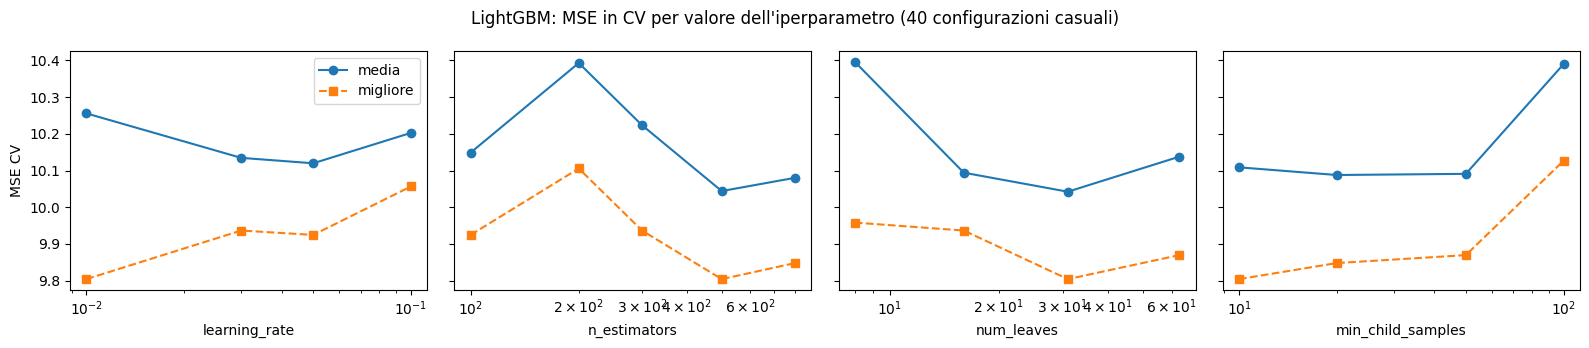

learning_rate      MSE CV medio: {0.01: 10.26, 0.03: 10.13, 0.05: 10.12, 0.1: 10.2}
n_estimators       MSE CV medio: {100.0: 10.15, 200.0: 10.39, 300.0: 10.22, 500.0: 10.04, 800.0: 10.08}
num_leaves         MSE CV medio: {8.0: 10.4, 16.0: 10.09, 31.0: 10.04, 63.0: 10.14}
min_child_samples  MSE CV medio: {10.0: 10.11, 20.0: 10.09, 50.0: 10.09, 100.0: 10.39}


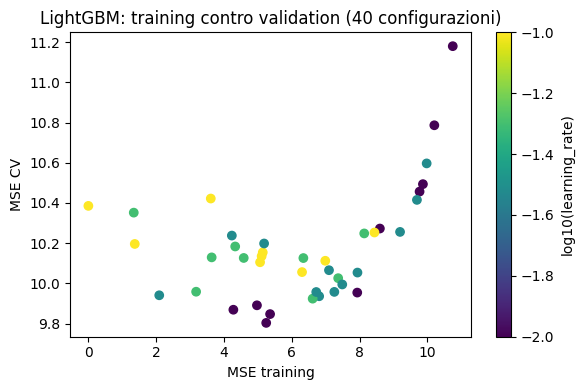

In [12]:
# Effetto dei singoli iperparametri: MSE CV medio (e migliore) delle configurazioni provate per ogni valore
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, p in zip(axes, ['learning_rate', 'n_estimators', 'num_leaves', 'min_child_samples']):
    g = lgbm_res.groupby(lgbm_res[f'param_model__{p}'].astype(float))['mse_cv']
    ax.plot(g.mean().index, g.mean().values, 'o-', label='media')
    ax.plot(g.min().index, g.min().values, 's--', label='migliore')
    ax.set_xlabel(p); ax.set_xscale('log')
axes[0].set_ylabel('MSE CV'); axes[0].legend()
plt.suptitle('LightGBM: MSE in CV per valore dell\'iperparametro (40 configurazioni casuali)')
plt.tight_layout(); plt.show()

for p in ['learning_rate', 'n_estimators', 'num_leaves', 'min_child_samples']:
    g = lgbm_res.groupby(lgbm_res[f'param_model__{p}'].astype(float))['mse_cv']
    print(f'{p:18s} MSE CV medio:', {k: round(v, 2) for k, v in g.mean().items()})

plt.figure(figsize=(6, 4))
plt.scatter(lgbm_res['mse_train'], lgbm_res['mse_cv'], c=np.log10(lgbm_res['param_model__learning_rate'].astype(float)), cmap='viridis')
plt.colorbar(label='log10(learning_rate)')
plt.xlabel('MSE training'); plt.ylabel('MSE CV'); plt.title('LightGBM: training contro validation (40 configurazioni)')
plt.tight_layout(); plt.show()

**Effetto dei singoli iperparametri.** Le differenze sono piccole (MSE medio per valore fra 10.04 e 10.40). Il
learning rate va letto insieme al numero di alberi: `learning_rate = 0.01` dà sia la configurazione migliore (9.80, con
500 alberi) sia, in media, l'errore più alto (10.26), perché con pochi alberi il modello resta in underfitting.
Penalizzano invece foglie molto grandi (`min_child_samples = 100`: media 10.39) e alberi molto piccoli
(`num_leaves = 8`: 10.40); 31 foglie hanno il valore migliore (10.04).

Il grafico training contro validation ha una forma a U: a destra (MSE di training sopra 8-9, soprattutto lr 0.01 con
pochi alberi) i modelli sono in **underfitting** e anche la validazione è peggiore; a sinistra (training vicino a 0,
lr 0.1 con molti alberi) sono in **overfitting** e la validazione peggiora di nuovo. Le configurazioni migliori stanno
in mezzo, con MSE di training intorno a 4-8.

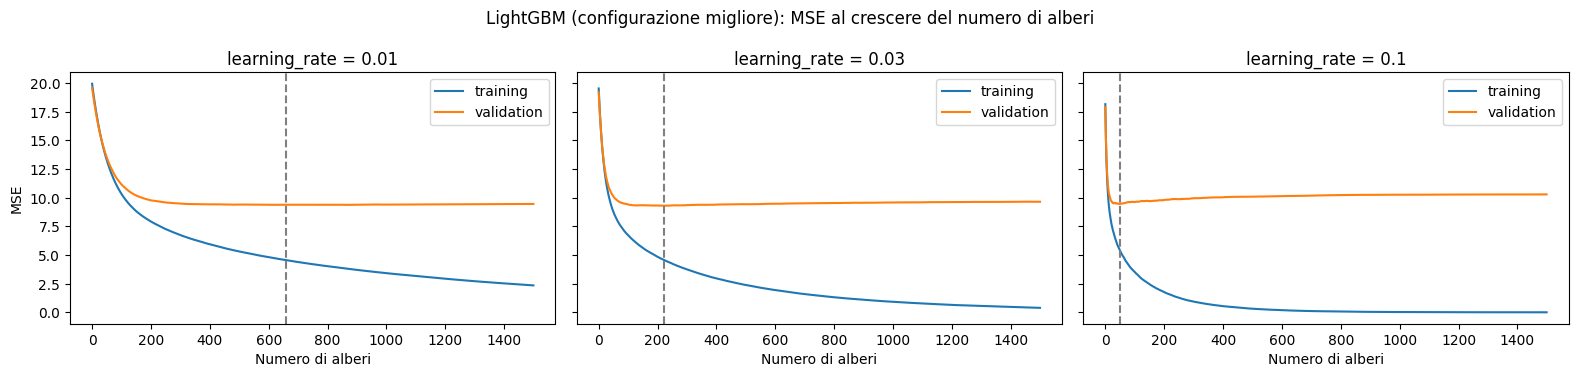

Tempo: 27.2 s


,learning_rate,alberi con MSE val minimo,MSE val minimo,MSE val a 1500,MSE train a 1500
0,0.01,658,9.375,9.457,2.349
1,0.03,223,9.301,9.647,0.391
2,0.10,51,9.455,10.288,0.002


In [13]:
t0 = time.time()

# Curva di apprendimento sul numero di alberi: si ritaglia un validation set (20%) dal training,
# si allena la configurazione migliore con 1500 alberi e si registra l'MSE ad ogni iterazione,
# per alcuni learning rate (0.01, 0.03, 0.1 e quello scelto in CV). Serve solo a descrivere il comportamento (la scelta resta quella della CV).
X_in, X_val, y_in, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
prep_in = clone(preprocessor).fit(X_in)
X_in_t, X_val_t = prep_in.transform(X_in), prep_in.transform(X_val)

lgbm_best_params = {k.replace('model__', ''): v for k, v in lgbm_search.best_params_.items()}
lrs = sorted({0.01, 0.03, 0.1, lgbm_best_params['learning_rate']})
fig, axes = plt.subplots(1, len(lrs), figsize=(5.3 * len(lrs), 3.8), sharey=True)
iter_rows = []
for ax, lr in zip(axes, lrs):
    params = {**lgbm_best_params, 'learning_rate': lr, 'n_estimators': 1500}
    m = LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **params)
    m.fit(X_in_t, y_in, eval_X=(X_in_t, X_val_t), eval_y=(y_in, y_val),
          eval_names=['training', 'validation'], eval_metric='l2')   # 'l2' = MSE in LightGBM
    tr, va = m.evals_result_['training']['l2'], m.evals_result_['validation']['l2']
    best_it = int(np.argmin(va)) + 1
    iter_rows.append({'learning_rate': lr, 'alberi con MSE val minimo': best_it,
                      'MSE val minimo': min(va), 'MSE val a 1500': va[-1],
                      'MSE train a 1500': tr[-1]})
    ax.plot(tr, label='training'); ax.plot(va, label='validation')
    ax.axvline(best_it, color='gray', ls='--')
    ax.set_title(f'learning_rate = {lr}'); ax.set_xlabel('Numero di alberi'); ax.legend()
axes[0].set_ylabel('MSE')
plt.suptitle('LightGBM (configurazione migliore): MSE al crescere del numero di alberi')
plt.tight_layout(); plt.show()
print(f'Tempo: {time.time() - t0:.1f} s')
pd.DataFrame(iter_rows).round(3)

**Numero di alberi e learning rate.** Con la configurazione migliore e un validation set ritagliato dal training,
l'errore di training scende sempre, mentre quello di validation raggiunge un minimo e poi risale lentamente:
- con `learning_rate = 0.1` il minimo arriva dopo circa **50 alberi** (MSE 9.46) e dopo 1500 alberi la validazione
  peggiora (10.29) mentre il training va praticamente a zero (0.002): **overfitting netto**;
- con `learning_rate = 0.03` il minimo arriva dopo circa **220 alberi** (MSE 9.30), con 9.65 a 1500 alberi;
- con `learning_rate = 0.01` il minimo arriva dopo circa **660 alberi** (MSE 9.38) e la curva è molto più piatta
  (9.46 a 1500 alberi).

I minimi dei tre learning rate sono vicini (9.30-9.46): un learning rate più basso non dà un modello molto migliore,
ma rende il risultato meno sensibile al numero di alberi. A differenza della Random Forest, nel boosting **troppi
alberi causano overfitting**, tanto più rapidamente quanto più il learning rate è alto. I 500 alberi con
`learning_rate = 0.01` scelti in CV sono vicini al minimo della curva.

> 📌 **Report** — grafico delle curve training/validation al crescere del numero di alberi per i diversi learning
> rate (affiancato alla curva OOB della Random Forest); frase: *"Nel boosting il numero di alberi e il learning rate
> vanno scelti insieme: con lr 0.1 il minimo dell'errore di validazione si raggiunge dopo circa 50 alberi e poi
> l'errore risale, con lr 0.01 servono circa 660 alberi ma la curva è più piatta."*

In [14]:
lgbm_final = make_pipe(LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
                                     **lgbm_best_params))
cv_rows.append(cv_scores(lgbm_final, 'LightGBM'))
show_cv_table(cv_rows)

,mse_train,mse_cv,mse_cv_std,rmse_train,rmse_cv,mae_train,mae_cv,r2_train,r2_cv,r2_cv_std
modello,,,,,,,,,,
Dummy (media),20.077,20.080,0.740,4.481,4.480,3.312,3.313,0.000,-0.000,0.000
Linear Regression,10.707,11.034,0.625,3.272,3.320,2.147,2.175,0.467,0.449,0.038
Ridge (alpha=316.228),10.738,10.993,0.595,3.277,3.314,2.152,2.174,0.465,0.452,0.036
Random Forest,4.386,9.751,0.625,2.094,3.121,1.239,1.977,0.782,0.513,0.042
LightGBM,5.248,9.804,0.729,2.291,3.129,1.531,1.986,0.739,0.510,0.047


LightGBM finale: **MSE CV 9.804, MAE CV 1.986, R² CV 0.510** (training: MSE 5.25, R² 0.739). È praticamente
equivalente alla Random Forest (R² CV 0.513), con un divario training-validation un po' più piccolo.

## 7. Confronto in cross-validation e robustezza

Il `best_score_` di una ricerca su molte configurazioni è una stima ottimistica (la configurazione migliore è anche
quella più favorita dal caso sui 5 fold usati per il tuning). Per questo i modelli finali si rivalutano con una
**CV ripetuta 3×5** con fold diversi (`random_state = 0`), come nel notebook di Gradient Boosting.

In [15]:
t0 = time.time()

# Il best_score_ di una ricerca su molte configurazioni è ottimistico: si rivalutano i modelli finali
# su una CV ripetuta 3x5 con fold diversi da quelli usati per il tuning (random_state diverso).
rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)
final_models = {
    'Ridge': ridge,
    'Random Forest': rf_final,
    'LightGBM': lgbm_final,
}
rcv_rows = []
for name, pipe in final_models.items():
    res = cross_validate(pipe, X_train, y_train, cv=rcv, scoring=SCORING, n_jobs=-1)
    rcv_rows.append({'modello': name,
                     'MSE (3x5)': -res['test_mse'].mean(), 'MSE std': res['test_mse'].std(),
                     'RMSE (3x5)': -res['test_rmse'].mean(),
                     'MAE (3x5)': -res['test_mae'].mean(),
                     'R2 (3x5)': res['test_r2'].mean(), 'R2 std': res['test_r2'].std()})
rcv_df = pd.DataFrame(rcv_rows).set_index('modello')
print(f'Tempo: {time.time() - t0:.1f} s')
rcv_df.round(3)

Tempo: 46.2 s


,MSE (3x5),MSE std,RMSE (3x5),MAE (3x5),R2 (3x5),R2 std
modello,,,,,,
Ridge,10.991,1.087,3.311,2.176,0.453,0.027
Random Forest,9.798,1.045,3.126,1.979,0.513,0.026
LightGBM,9.850,1.059,3.134,1.990,0.510,0.027


Sui nuovi fold i risultati sono quasi identici a quelli del tuning: Random Forest **R² 0.513** (MSE 9.80), LightGBM
**0.510** (9.85), Ridge 0.453 (10.99). L'ottimismo della ricerca è trascurabile (≤ 0.05 di MSE). La differenza fra i
due modelli non lineari (0.05 di MSE, 0.003 di R²) è molto più piccola della deviazione standard fra i fold (≈ 1.05 di
MSE, ≈ 0.03 di R²): **i due modelli sono equivalenti**. Il guadagno sul lineare (≈ 0.06 di R², ≈ 1.2 di MSE) è invece
sistematico.

In [16]:
cv_table = show_cv_table(cv_rows)
cv_table['gap MSE (cv - train)'] = (cv_table['mse_cv'] - cv_table['mse_train']).round(3)
cv_table

,mse_train,mse_cv,mse_cv_std,rmse_train,rmse_cv,mae_train,mae_cv,r2_train,r2_cv,r2_cv_std,gap MSE (cv - train)
modello,,,,,,,,,,,
Dummy (media),20.077,20.080,0.740,4.481,4.480,3.312,3.313,0.000,-0.000,0.000,0.003
Linear Regression,10.707,11.034,0.625,3.272,3.320,2.147,2.175,0.467,0.449,0.038,0.327
Ridge (alpha=316.228),10.738,10.993,0.595,3.277,3.314,2.152,2.174,0.465,0.452,0.036,0.255
Random Forest,4.386,9.751,0.625,2.094,3.121,1.239,1.977,0.782,0.513,0.042,5.365
LightGBM,5.248,9.804,0.729,2.291,3.129,1.531,1.986,0.739,0.510,0.047,4.556


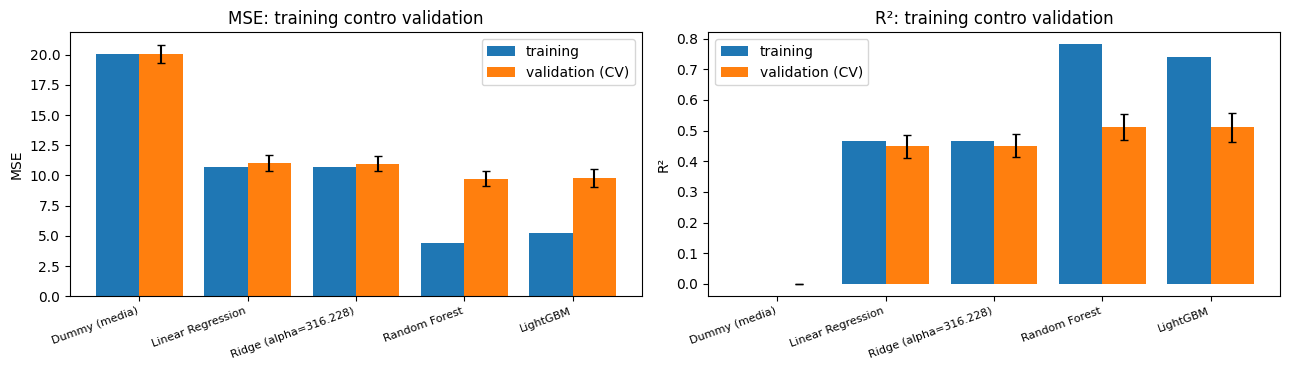

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
t = pd.DataFrame(cv_rows).set_index('modello')
x = np.arange(len(t))
for ax, m, lab in [(axes[0], 'mse', 'MSE'), (axes[1], 'r2', 'R²')]:
    ax.bar(x - 0.2, t[f'{m}_train'], 0.4, label='training')
    ax.bar(x + 0.2, t[f'{m}_cv'], 0.4, yerr=t[f'{m}_cv_std'], capsize=3, label='validation (CV)')
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=20, ha='right', fontsize=8)
    ax.set_ylabel(lab); ax.legend()
axes[0].set_title('MSE: training contro validation'); axes[1].set_title('R²: training contro validation')
plt.tight_layout(); plt.show()

**Tabella riassuntiva in CV.** I due modelli non lineari riducono l'MSE da 10.99 (Ridge) a 9.75-9.80 e il MAE da 2.17
a 1.98, portando l'R² da 0.45 a 0.51. Hanno però un divario training-validation molto più grande (MSE: +5.4 per la
Random Forest, +4.6 per LightGBM, contro +0.26 del Ridge): adattano molto il training, ma questo non peggiora la
validazione, che resta la migliore.

> 📌 **Report** — tabella con MSE, MAE e R² su training e CV (± dev. std) per tutti i modelli e il grafico a barre
> training contro validation; frase: *"I modelli non lineari spiegano circa il 51% della varianza del BMI contro il
> 45% del modello lineare; Random Forest e LightGBM sono equivalenti (differenza ben dentro la variabilità fra i
> fold)."*

## 8. Valutazione finale sul test set

Ogni modello viene riallenato su tutto il training con gli iperparametri scelti in CV e valutato una sola volta
sulle 1692 righe di test (le stesse dei notebook di classificazione).

In [18]:
t0 = time.time()

all_models = {
    'Dummy (media)': dummy,
    'Linear Regression': linreg,
    'Ridge': ridge,
    'Random Forest': rf_final,
    'LightGBM': lgbm_final,
}
fitted, preds_test, test_rows = {}, {}, []
for name, pipe in all_models.items():
    p = clone(pipe).fit(X_train, y_train)
    fitted[name] = p
    preds_test[name] = p.predict(X_test)
    tr = reg_metrics(y_train, p.predict(X_train))
    te = reg_metrics(y_test, preds_test[name])
    test_rows.append({'modello': name,
                      'MSE train': tr['MSE'], 'MSE test': te['MSE'],
                      'RMSE train': tr['RMSE'], 'RMSE test': te['RMSE'],
                      'MAE train': tr['MAE'], 'MAE test': te['MAE'],
                      'R2 train': tr['R2'], 'R2 test': te['R2']})
test_df = pd.DataFrame(test_rows).set_index('modello')
print(f'Tempo: {time.time() - t0:.1f} s')
test_df.round(3)

Tempo: 14.9 s


,MSE train,MSE test,RMSE train,RMSE test,MAE train,MAE test,R2 train,R2 test
modello,,,,,,,,
Dummy (media),20.077,19.614,4.481,4.429,3.312,3.216,0.000,-0.001
Linear Regression,10.739,9.577,3.277,3.095,2.147,2.093,0.465,0.511
Ridge,10.761,9.559,3.280,3.092,2.152,2.094,0.464,0.512
Random Forest,4.368,8.788,2.090,2.964,1.232,1.910,0.782,0.551
LightGBM,5.757,8.837,2.399,2.973,1.592,1.922,0.713,0.549


**Risultati sul test.**

| Modello | MSE | RMSE | MAE | R² |
|---|---|---|---|---|
| Dummy (media) | 19.61 | 4.43 | 3.22 | 0.000 |
| Linear Regression | 9.58 | 3.10 | 2.09 | 0.511 |
| Ridge | 9.56 | 3.09 | 2.09 | 0.512 |
| **Random Forest** | **8.79** | **2.96** | **1.91** | **0.551** |
| LightGBM | 8.84 | 2.97 | 1.92 | 0.549 |

I valori sul test sono un po' migliori di quelli in CV per tutti i modelli (Ridge 0.512 contro 0.452, Random Forest
0.551 contro 0.513): la differenza è dentro la variabilità fra i fold (dev. std dell'R² ≈ 0.04) e riguarda tutti i
modelli allo stesso modo, quindi **l'ordine e le distanze fra i modelli sono gli stessi**. La Random Forest ha i
valori più alti su tutte le metriche, con un margine su LightGBM trascurabile (0.05 di MSE). Rispetto al Ridge i
modelli non lineari guadagnano circa 0.04 di R², 0.7-0.8 di MSE e 0.18 di MAE; l'errore tipico è di circa **1.9 punti
di BMI**, su un BMI medio di 19.3.

> 📌 **Report** — tabella del test set (MSE, MAE, R², con l'RMSE come colonna aggiuntiva e i valori sul training per l'overfitting); frase: *"Sul test
> la Random Forest ha R² 0.55 e MAE 1.9 (LightGBM 0.55 e 1.9), contro 0.51 e 2.1 del modello lineare: il guadagno dei
> modelli non lineari è reale ma contenuto."*

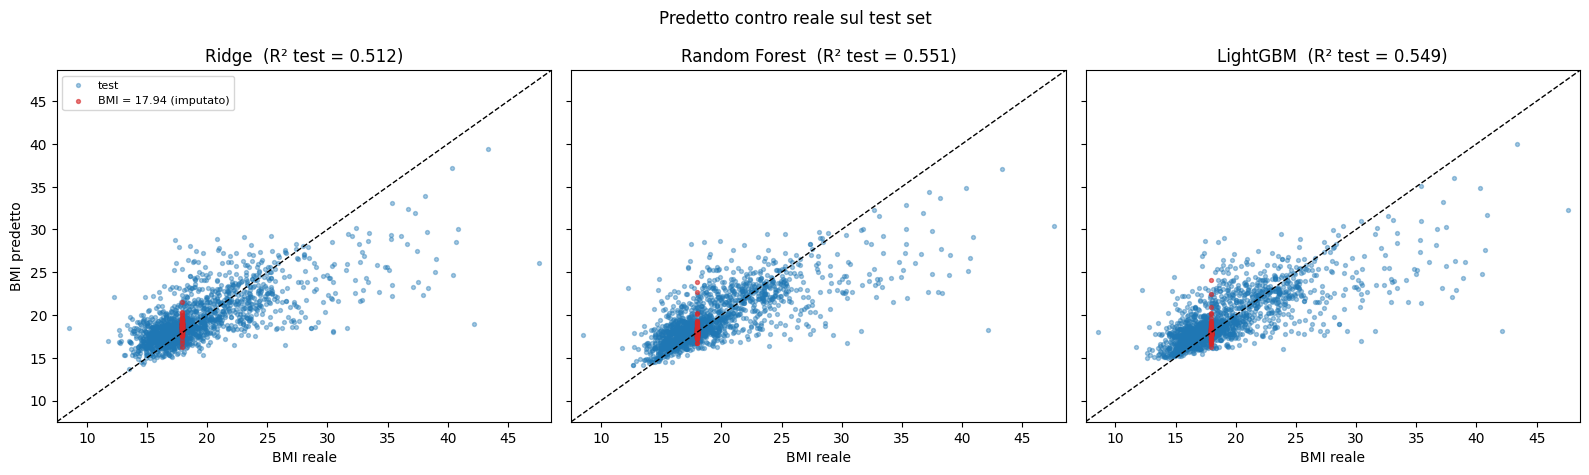

In [19]:
show = ['Ridge', 'Random Forest', 'LightGBM']
lims = [y_test.min() - 1, y_test.max() + 1]
imp_test = np.isclose(y_test, IMPUTED_BMI)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, name in zip(axes, show):
    ax.scatter(y_test[~imp_test], preds_test[name][~imp_test], s=8, alpha=0.4, label='test')
    ax.scatter(y_test[imp_test], preds_test[name][imp_test], s=8, alpha=0.6, color='tab:red',
               label=f'BMI = {IMPUTED_BMI} (imputato)')
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f"{name}  (R² test = {test_df.loc[name, 'R2 test']:.3f})")
    ax.set_xlabel('BMI reale')
axes[0].set_ylabel('BMI predetto'); axes[0].legend(fontsize=8)
plt.suptitle('Predetto contro reale sul test set')
plt.tight_layout(); plt.show()

**Predetto contro reale.** Per tutti e tre i modelli i punti sono distribuiti attorno alla diagonale nella zona
centrale (BMI 15-22), mentre per i BMI alti le predizioni stanno **sotto la diagonale**: i valori estremi sono
sistematicamente sottostimati: per BMI reali sopra 35 le predizioni stanno quasi tutte fra 20 e 35. Ridge ha una
nuvola più larga nella zona centrale. I punti rossi (BMI imputato a 17.94) formano una colonna verticale: per la
Random Forest e LightGBM le predizioni di queste righe sono concentrate vicino al valore imputato (circa 16.5-19,
con pochi casi più alti), per il Ridge sono più disperse.

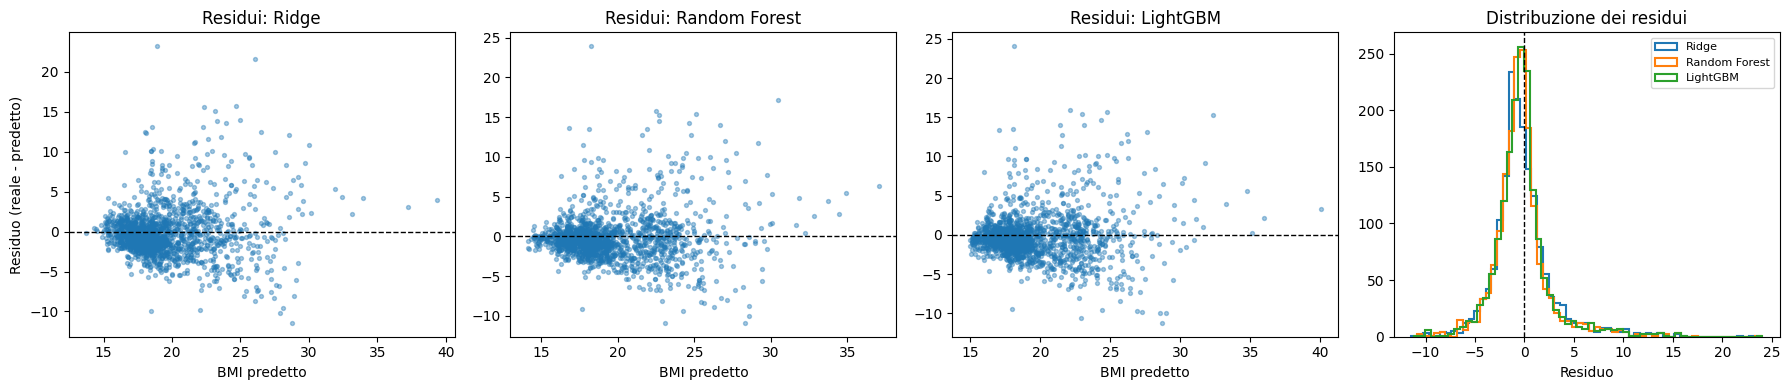

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes[:3], show):
    res_ = y_test.values - preds_test[name]
    ax.scatter(preds_test[name], res_, s=8, alpha=0.4)
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_title(f'Residui: {name}'); ax.set_xlabel('BMI predetto')
axes[0].set_ylabel('Residuo (reale - predetto)')
for name in show:
    axes[3].hist(y_test.values - preds_test[name], bins=60, histtype='step', lw=1.5, label=name)
axes[3].axvline(0, color='k', ls='--', lw=1)
axes[3].set_title('Distribuzione dei residui'); axes[3].set_xlabel('Residuo'); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Residui.** Per predizioni basse (BMI predetto 15-19) i residui sono piccoli e centrati sullo zero; per predizioni
più alte la dispersione cresce molto, in entrambe le direzioni: l'errore aumenta con il BMI (eteroschedasticità). I
residui più grandi sono positivi (fino a circa +24, cioè BMI molto alti predetti come normali). La distribuzione dei
residui ha un picco sullo zero e una coda lunga a destra; le tre distribuzioni sono quasi sovrapposte.

In [21]:
# Errore per fascia di BMI reale (quintili del test set): MAE e media dei residui (reale - predetto)
bins = pd.qcut(y_test, 5)
rows = []
for name in show:
    r = pd.DataFrame({'bin': bins, 'res': y_test.values - preds_test[name]})
    g = r.groupby('bin', observed=True)['res']
    rows.append(pd.DataFrame({'modello': name, 'n': g.size(), 'MAE': g.apply(lambda s: s.abs().mean()),
                              'media residui (reale - predetto)': g.mean()}))
bin_df = pd.concat(rows).reset_index().rename(columns={'bin': 'fascia BMI reale'})
bin_df.pivot(index='fascia BMI reale', columns='modello', values=['MAE', 'media residui (reale - predetto)']).round(2)

MAE                      \
modello          LightGBM Random Forest Ridge   
fascia BMI reale                                
(8.519, 16.23]       1.92          1.84  2.17   
(16.23, 17.554]      1.40          1.41  1.45   
(17.554, 18.632]     1.01          1.01  1.22   
(18.632, 21.926]     1.71          1.71  1.67   
(21.926, 47.6]       3.56          3.57  3.96   

                 media residui (reale - predetto)                      
modello                                  LightGBM Random Forest Ridge  
fascia BMI reale                                                       
(8.519, 16.23]                              -1.91         -1.81 -2.14  
(16.23, 17.554]                             -1.20         -1.23 -1.16  
(17.554, 18.632]                            -0.55         -0.59 -0.72  
(18.632, 21.926]                            -0.39         -0.48 -0.30  
(21.926, 47.6]                               3.02          3.02  3.36

**Errore per fascia di BMI reale (quintili del test set).** La media dei residui (reale − predetto) indica se in una
fascia il modello tende a sottostimare (valori positivi) o a sovrastimare (valori negativi).
- Nella fascia centrale (17.6-18.6) l'errore è minimo (MAE ≈ 1.0 per i modelli ad albero, 1.2 per il Ridge).
- Nel quintile più alto (BMI > 21.9) il MAE sale a **3.6** (Ridge 4.0) con una media dei residui di **+3.0**: i BMI alti vengono
  sottostimati in media di 3 punti.
- Nel quintile più basso (BMI < 16.2) la media dei residui è −1.8/−1.9 (Ridge −2.1): i BMI bassi vengono sovrastimati.

È la **regressione verso la media**: con un segnale che spiega circa metà della varianza, le predizioni vengono
"tirate" verso il centro della distribuzione. I modelli non lineari riducono un po' l'errore agli estremi
rispetto al Ridge, ma non risolvono il problema. È lo stesso fenomeno della classificazione, dove le classi
estreme (classe 3) erano le più difficili.

> 📌 **Report** — grafico predetto contro reale per Ridge, Random Forest e LightGBM, grafico dei residui e tabella
> MAE e media dei residui per fascia di BMI; frase: *"Tutti i modelli sottostimano i BMI alti (in media di 3 punti nel quintile più alto)
> e sovrastimano quelli bassi: è un effetto di regressione verso la media, coerente con un segnale che spiega circa
> metà della varianza."*

## 9. Feature importance

Analisi **descriptive** dei due modelli non lineari, con i due metodi usati nel notebook del corso sugli ensemble
(prime 15 feature):
- **MDI** (`feature_importances_`, Mean Decrease in Impurity): per ogni feature, la riduzione dell'errore quadratico
  ottenuta dagli split su quella feature, sommata su tutti gli alberi. Per LightGBM si usa l'equivalente
  `importance_type='gain'`, normalizzato a somma 1 per confrontarlo con la Random Forest. È calcolata sul training e
  tende a favorire le feature continue con molti valori distinti.
- **Permutation importance** sul test set (10 ripetizioni): calo di R² quando si permutano a caso i valori di una
  colonna. È calcolata su dati non visti ed è confrontabile fra modelli diversi; le colonne `*-Season` vengono
  permutate per intero (prima del one-hot encoding).

Non è un'analisi di explainability (che verrà fatta a parte): serve solo a capire su quali informazioni si basano i
modelli e a confrontarle con la classificazione.

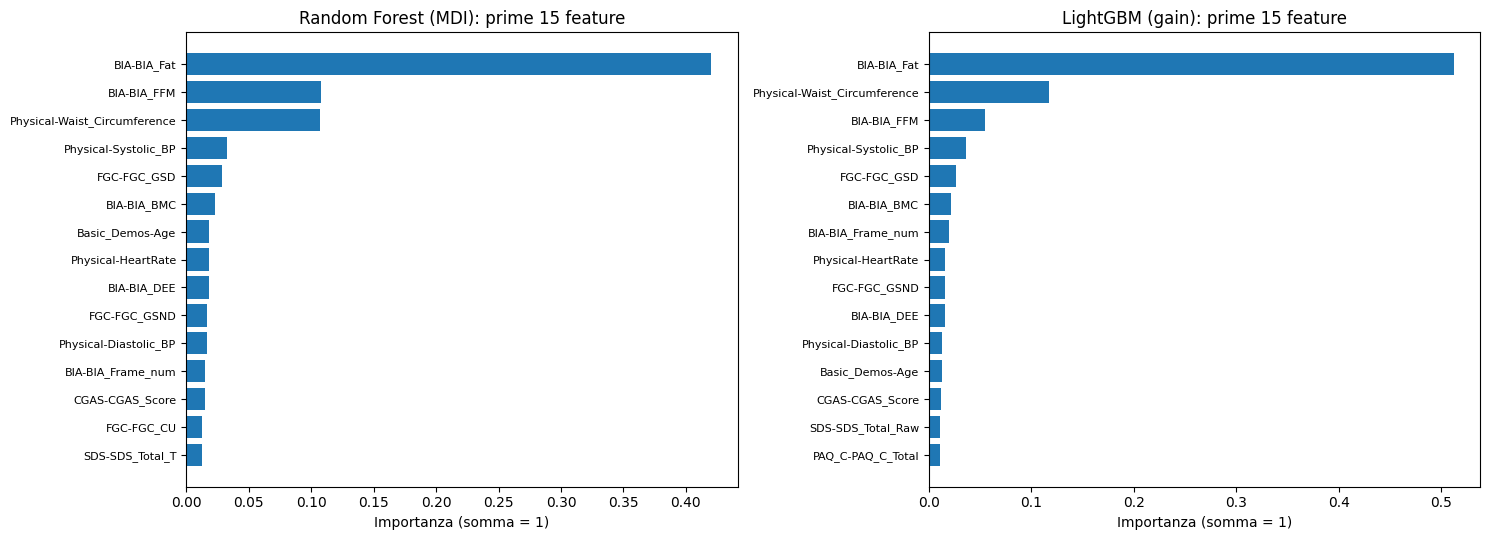

Random Forest (MDI): le prime 5 feature coprono il 69.6% dell'importanza, le prime 10 il 79.0%
LightGBM (gain): le prime 5 feature coprono il 74.7% dell'importanza, le prime 10 il 83.6%
Correlazione di Spearman fra le due classifiche: 0.940


,Random Forest (MDI),LightGBM (gain)
BIA-BIA_Fat,0.420,0.512
BIA-BIA_FFM,0.107,0.055
Physical-Waist_Circumference,0.107,0.117
Physical-Systolic_BP,0.033,0.036
FGC-FGC_GSD,0.029,0.026
BIA-BIA_BMC,0.023,0.022
Basic_Demos-Age,0.018,0.013
Physical-HeartRate,0.018,0.016
BIA-BIA_DEE,0.018,0.015
FGC-FGC_GSND,0.017,0.016


In [22]:
# Importanza MDI (Mean Decrease in Impurity): per i modelli ad albero è la riduzione dell'errore quadratico
# ottenuta dagli split su ciascuna feature, sommata su tutti gli alberi (come nel notebook del corso, prime 15 feature).
# Per LightGBM si usa importance_type='gain' (riduzione della loss), normalizzata a somma 1 per confrontarla con la RF.
NBR_FEATURES = 15
feat_names = fitted['Random Forest'].named_steps['prep'].get_feature_names_out()
feat_names = np.array([f.split('__', 1)[1] for f in feat_names])

rf_imp = fitted['Random Forest'].named_steps['model'].feature_importances_
lgbm_gain = fitted['LightGBM'].named_steps['model'].booster_.feature_importance(importance_type='gain')
lgbm_imp = lgbm_gain / lgbm_gain.sum()
imp_df = pd.DataFrame({'Random Forest (MDI)': rf_imp, 'LightGBM (gain)': lgbm_imp}, index=feat_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, col in zip(axes, imp_df.columns):
    top = imp_df[col].sort_values().tail(NBR_FEATURES)
    ax.barh(np.arange(len(top)), top.values)
    ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=8)
    ax.set_title(f'{col}: prime {NBR_FEATURES} feature'); ax.set_xlabel('Importanza (somma = 1)')
plt.tight_layout(); plt.show()

for col in imp_df.columns:
    srt = imp_df[col].sort_values(ascending=False)
    print(f'{col}: le prime 5 feature coprono il {srt.head(5).sum()*100:.1f}% dell\'importanza, '
          f'le prime 10 il {srt.head(10).sum()*100:.1f}%')
print(f"Correlazione di Spearman fra le due classifiche: {imp_df.corr(method='spearman').iloc[0, 1]:.3f}")
imp_df.sort_values('Random Forest (MDI)', ascending=False).head(NBR_FEATURES).round(3)

**MDI.** L'importanza è molto **concentrata**: `BIA_Fat` (massa grassa) da sola vale il 42% nella Random Forest e il
51% in LightGBM; seguono `BIA_FFM` (massa magra, 11% / 6%) e la circonferenza vita (11% / 12%). Dopo queste tre
feature l'importanza crolla (pressione sistolica 3%, forza di presa `FGC_GSD` 3%, `BIA_BMC` 2%): le prime 5 feature
coprono il 70% (Random Forest) e il 75% (LightGBM) del totale. Le due classifiche sono molto simili (correlazione di
Spearman 0.94).

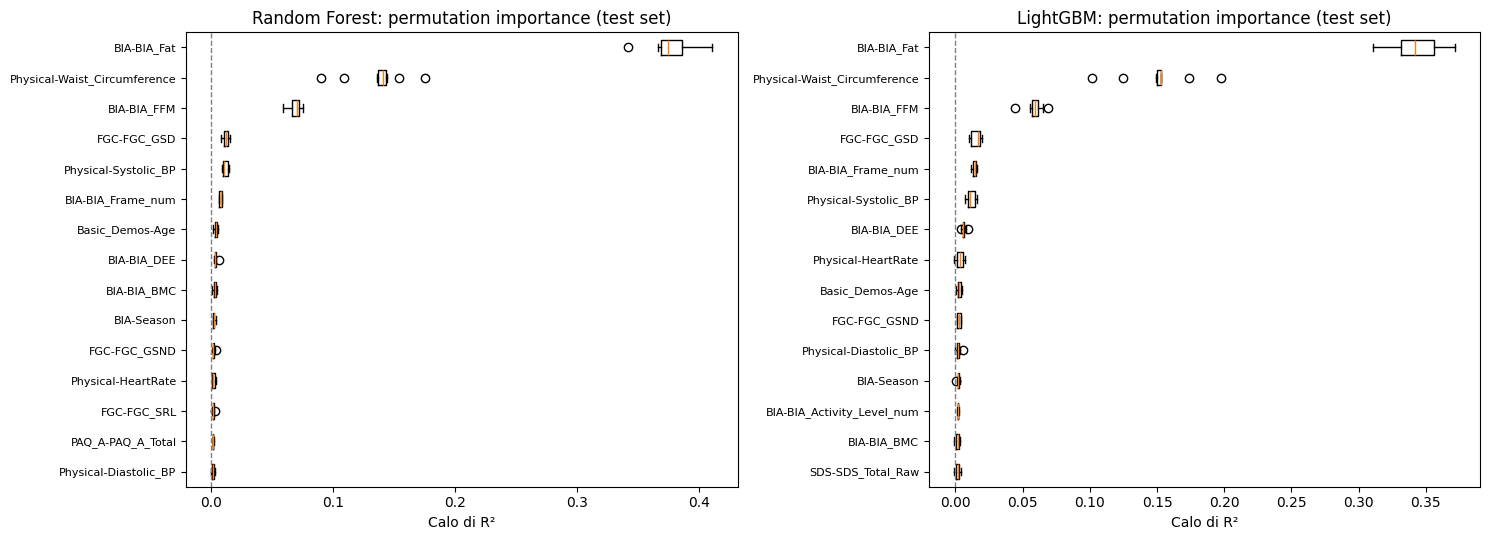

Tempo: 12.0 s
Feature con calo di R² medio <= 0 per entrambi i modelli: 6 su 45


,Random Forest (calo R²),LightGBM (calo R²)
BIA-BIA_Fat,0.3774,0.3431
Physical-Waist_Circumference,0.1369,0.1509
BIA-BIA_FFM,0.0689,0.0590
FGC-FGC_GSD,0.0119,0.0153
Physical-Systolic_BP,0.0112,0.0118
BIA-BIA_Frame_num,0.0077,0.0141
Basic_Demos-Age,0.0038,0.0028
BIA-BIA_DEE,0.0034,0.0060
BIA-BIA_BMC,0.0028,0.0017
BIA-Season,0.0022,0.0019


In [23]:
t0 = time.time()

# Permutation importance sul test set (come nel notebook del corso): calo di R² quando si permutano a caso i valori
# di una colonna originale (le colonne *-Season vengono permutate per intero, prima del one-hot encoding).
# A differenza della MDI è calcolata su dati non visti ed è confrontabile fra modelli diversi.
perm = {}
for name in ['Random Forest', 'LightGBM']:
    perm[name] = permutation_importance(fitted[name], X_test, y_test, scoring='r2',
                                        n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, name in zip(axes, perm):
    r = perm[name]
    idx = r.importances_mean.argsort()[-NBR_FEATURES:]
    try:                                                     # matplotlib >= 3.10
        ax.boxplot(r.importances[idx].T, orientation='horizontal')
    except TypeError:                                        # versioni precedenti
        ax.boxplot(r.importances[idx].T, vert=False)
    ax.set_yticks(np.arange(1, len(idx) + 1)); ax.set_yticklabels(X_test.columns[idx], fontsize=8)
    ax.axvline(0, color='gray', ls='--', lw=1)
    ax.set_title(f'{name}: permutation importance (test set)'); ax.set_xlabel('Calo di R²')
plt.tight_layout(); plt.show()

perm_df = pd.DataFrame({f'{n} (calo R²)': perm[n].importances_mean for n in perm}, index=X_test.columns)
print(f'Tempo: {time.time() - t0:.1f} s')
print(f"Feature con calo di R² medio <= 0 per entrambi i modelli: {int((perm_df <= 0).all(axis=1).sum())} su {len(perm_df)}")
perm_df.sort_values('Random Forest (calo R²)', ascending=False).head(NBR_FEATURES).round(4)

**Permutation importance (test).** Conferma il quadro della MDI: permutando `BIA_Fat` l'R² cala di 0.38 (Random Forest)
e 0.34 (LightGBM), la circonferenza vita di 0.14-0.15, `BIA_FFM` di 0.06-0.07. Tutte le altre feature causano un calo
di al massimo 0.015 (forza di presa, pressione sistolica, `BIA_Frame_num`); 6 colonne su 45 hanno un calo medio ≤ 0
per entrambi i modelli. Rispetto alla MDI, la permutation importance mette la circonferenza vita davanti a `BIA_FFM`
anche nella Random Forest.

**Interpretazione.**
- Il BMI viene previsto quasi solo dalla **composizione corporea** (massa grassa e magra) e dalla **circonferenza
  vita**, cioè misure fisicamente legate al peso. L'età, pur correlata con il BMI (0.41), ha importanza bassa (calo
  di R² 0.003-0.004): la sua informazione è già contenuta nelle misure BIA, con cui è correlata.
- **Attività fisica dichiarata (PAQ), sonno e ore di internet contano pochissimo**: compaiono solo in fondo alla
  classifica o non compaiono fra le prime 15, con cali di R² inferiori a 0.003. Dei test di fitness conta un po' solo
  la forza di presa (`FGC_GSD`, calo 0.012-0.015). Una volta nota la composizione corporea, le abitudini aggiungono
  poca informazione sul BMI.
- **Confronto con la classificazione di `sii`:** lo stesso gruppo di feature (misure antropometriche e BIA) è in
  testa anche lì, ma nella classificazione l'importanza era diffusa (le prime 10 feature coprivano meno della metà
  del totale). Qui le prime 10 coprono il 79-84%: il segnale della regressione è più forte e concentrato su poche
  variabili.
- **Attenzione:** massa grassa e massa magra sono per costruzione parti del peso (nel dataset `BIA_Fat + BIA_FFM` ha
  correlazione 0.76 con il peso). Peso e altezza sono stati esclusi, ma parte della loro informazione rientra
  attraverso le misure BIA: va dichiarato nel report come forma attenuata di leakage.

> 📌 **Report** — grafico della permutation importance sul test (preferibile alla MDI perché su dati non visti) o i
> due grafici MDI affiancati; frase: *"Entrambi i modelli si basano quasi solo su massa grassa (BIA_Fat), circonferenza
> vita e massa magra (calo di R² di 0.34-0.38, 0.14-0.15 e 0.06-0.07 permutandole); attività fisica dichiarata,
> sonno e ore di internet contano pochissimo."* Dichiarare che le misure BIA reintroducono in parte l'informazione del peso.

## 10. Regressione senza le righe con BMI imputato

Le 609 righe con BMI = 17.94 hanno un target che non è una misura ma il valore usato per l'imputazione. Si ripete
la regressione **escludendole** e si confrontano i risultati con quelli ottenuti sul dataset intero.

**Impostazione.**
- Stesso split di prima: le righe imputate si tolgono sia dal training sia dal test, quindi il test "pulito"
  contiene le stesse righe di prima tranne le 111 imputate.
- **Stessi iperparametri** scelti sul dataset intero (nessun nuovo tuning): così la differenza dipende solo dai
  dati usati e il tempo di esecuzione resta contenuto.
- Tre confronti: (A) modello allenato sul dataset intero, valutato sul test intero (risultati della sezione 8);
  (B) stesso modello, valutato solo sulle righe non imputate del test; (C) modello allenato senza righe imputate,
  valutato sulle righe non imputate del test. (B) contro (C) misura l'effetto di togliere le righe imputate dal
  training a parità di test.

In [24]:
# Stesso split di prima: si tolgono le righe con BMI imputato sia dal training sia dal test
keep_tr = ~np.isclose(y_train, IMPUTED_BMI)
keep_te = ~np.isclose(y_test, IMPUTED_BMI)
X_train_c, y_train_c = X_train[keep_tr], y_train[keep_tr]
X_test_c, y_test_c = X_test[keep_te], y_test[keep_te]
print(f'Training: {len(y_train)} -> {len(y_train_c)} righe ({(~keep_tr).sum()} rimosse)')
print(f'Test:     {len(y_test)} -> {len(y_test_c)} righe ({(~keep_te).sum()} rimosse)')
print(f'Dev. std del BMI: training {y_train.std():.3f} -> {y_train_c.std():.3f}, '
      f'test {y_test.std():.3f} -> {y_test_c.std():.3f}')

# Le righe con BMI imputato hanno spesso imputate anche le altre misure fisiche (valore più frequente della colonna)?
imp_all = np.isclose(y, IMPUTED_BMI)
check = []
for c in ['BIA-BIA_Fat', 'BIA-BIA_FFM', 'Physical-Waist_Circumference', 'Physical-Systolic_BP']:
    mode = df[c].mode()[0]
    check.append({'colonna': c, 'valore più frequente': mode,
                  '% righe BMI imputato': 100 * np.isclose(df.loc[imp_all, c], mode).mean(),
                  '% altre righe': 100 * np.isclose(df.loc[~imp_all, c], mode).mean()})
pd.DataFrame(check).set_index('colonna').round(1)

Training: 6768 -> 6270 righe (498 rimosse)
Test:     1692 -> 1581 righe (111 rimosse)
Dev. std del BMI: training 4.481 -> 4.634, test 4.427 -> 4.565


,valore più frequente,% righe BMI imputato,% altre righe
colonna,,,
BIA-BIA_Fat,16.2,78.2,14.9
BIA-BIA_FFM,61.1,79.0,15.1
Physical-Waist_Circumference,26.0,72.9,26.9
Physical-Systolic_BP,114.0,57.1,5.6


Si tolgono 498 righe dal training (6270 restanti) e 111 dal test (1581 restanti). Togliendo un valore centrale ripetuto,
la deviazione standard del BMI aumenta (training da 4.48 a 4.63): il task senza imputati ha un MSE più alto anche a
parità di qualità del modello, perché l'MSE dipende dalla varianza del target; per il confronto conta soprattutto
l'R².

Le righe con BMI imputato hanno **spesso imputate anche le altre misure fisiche**: circa il 78% ha `BIA_Fat` uguale
al suo valore più frequente (contro il 15% delle altre righe), e valori simili si trovano per `BIA_FFM` (79% contro 15%), la
circonferenza vita (73% contro 27%) e la pressione sistolica (57% contro 6%). Sono quindi soggetti per cui mancavano in origine quasi tutte le misure fisiche.

In [25]:
# Quanto sbagliano i modelli (allenati sul dataset intero) sulle righe imputate e sulle altre righe del test
rows = []
for name in ['Dummy (media)'] + show:
    p = preds_test[name]
    rows.append({'modello': name,
                 'MAE righe imputate': mean_absolute_error(y_test[~keep_te], p[~keep_te]),
                 'MAE altre righe': mean_absolute_error(y_test[keep_te], p[keep_te]),
                 'predizione media sulle righe imputate': p[~keep_te].mean()})
pd.DataFrame(rows).set_index('modello').round(3)

,MAE righe imputate,MAE altre righe,predizione media sulle righe imputate
modello,,,
Dummy (media),1.527,3.335,19.467
Ridge,0.809,2.185,18.636
Random Forest,0.487,2.010,18.144
LightGBM,0.514,2.021,18.079


Sulle righe imputate i modelli (allenati sul dataset intero) sbagliano **poco**: MAE 0.49 per la Random Forest e
0.51 per LightGBM, contro circa 2.0 sulle altre righe; la predizione media su queste righe è circa 18.1, molto vicina a
17.94. Poiché anche le feature sono imputate, i modelli riconoscono questo "profilo imputato" e predicono il valore
imputato. Queste righe **non aggiungono rumore**: sono, al contrario, i casi più facili del test.

In [26]:
t0 = time.time()

# Stessi iperparametri scelti sul dataset intero (nessun nuovo tuning): si isola l'effetto dei dati
clean_rows, cv_clean_rows = [], []
for name, pipe in all_models.items():
    if name == 'Linear Regression':
        continue
    cv_clean_rows.append(cv_scores(pipe, name, X_train_c, y_train_c))
    p_clean = clone(pipe).fit(X_train_c, y_train_c)
    m_full_on_clean = reg_metrics(y_test_c, preds_test[name][keep_te])    # allenato sul dataset intero
    m_clean = reg_metrics(y_test_c, p_clean.predict(X_test_c))             # allenato senza righe imputate
    clean_rows.append({'modello': name,
                       'MSE test intero (A)': test_df.loc[name, 'MSE test'],
                       'R2 test intero (A)': test_df.loc[name, 'R2 test'],
                       'MSE test pulito (B)': m_full_on_clean['MSE'],
                       'R2 test pulito (B)': m_full_on_clean['R2'],
                       'MSE test pulito (C)': m_clean['MSE'],
                       'MAE test pulito (C)': m_clean['MAE'],
                       'R2 test pulito (C)': m_clean['R2']})
clean_df = pd.DataFrame(clean_rows).set_index('modello')
print(f'Tempo: {time.time() - t0:.1f} s')
clean_df.round(3)

Tempo: 27.2 s


,MSE test intero (A),R2 test intero (A),MSE test pulito (B),R2 test pulito (B),MSE test pulito (C),MAE test pulito (C),R2 test pulito (C)
modello,,,,,,,
Dummy (media),19.614,-0.001,20.827,-0.000,20.857,3.371,-0.002
Ridge,9.559,0.512,10.162,0.512,10.205,2.200,0.510
Random Forest,8.788,0.551,9.346,0.551,9.401,2.019,0.549
LightGBM,8.837,0.549,9.391,0.549,9.453,2.030,0.546


**Confronto.**
- (A) → (B): valutando i modelli del dataset intero solo sulle righe non imputate, l'MSE sale (Random Forest da 8.79
  a 9.35) perché si tolgono i casi più facili, ma l'R² resta uguale (0.551), perché cresce anche la varianza del
  target.
- (B) → (C): allenare i modelli senza le righe imputate **non cambia i risultati** (Random Forest R² 0.551 → 0.549,
  LightGBM 0.549 → 0.546, Ridge 0.512 → 0.510; differenze di MSE ≤ 0.06). L'ordine dei modelli resta lo stesso.

In [27]:
cv_clean = show_cv_table(cv_clean_rows)
cv_full = show_cv_table(cv_rows).drop(index='Linear Regression')
cv_full.index = cv_clean.index
pd.concat({'CV dataset intero': cv_full[['mse_cv', 'r2_cv', 'r2_cv_std']],
           'CV senza righe imputate': cv_clean[['mse_train', 'mse_cv', 'r2_cv', 'r2_cv_std']]}, axis=1)

CV dataset intero                  CV senza righe imputate  \
                         mse_cv  r2_cv r2_cv_std               mse_train   
modello                                                                    
Dummy (media)            20.080 -0.000     0.000                  21.471   
Ridge                    10.993  0.452     0.036                  11.501   
Random Forest             9.751  0.513     0.042                   4.676   
LightGBM                  9.804  0.510     0.047                   5.567   

                                        
               mse_cv  r2_cv r2_cv_std  
modello                                 
Dummy (media)  21.479 -0.001     0.001  
Ridge          11.751  0.454     0.035  
Random Forest  10.516  0.512     0.038  
LightGBM       10.543  0.510     0.040

In CV senza righe imputate l'R² è praticamente identico a quello sul dataset intero (Random Forest 0.512 contro 0.513,
LightGBM 0.510 contro 0.510, Ridge 0.454 contro 0.452), mentre l'MSE è più alto (Random Forest 10.52 contro 9.75) solo per
la maggiore varianza del target.

**Conclusione.** Le righe con BMI imputato non peggiorano né migliorano l'apprendimento: i modelli le riconoscono
dalle feature, anch'esse imputate, e le predicono bene. Le conclusioni della regressione non dipendono quindi
dall'imputazione del target, e il modello sul dataset intero può essere tenuto come risultato principale. Le metriche
calcolate sul dataset intero vanno lette sapendo che il 7% delle righe è "facile" per costruzione (abbassa l'MSE ma
non cambia l'R²).

> 📌 **Report** — tabella (A)/(B)/(C) con MSE e R²; frase: *"Escludere le 609 righe con BMI imputato non cambia
> l'R² (Random Forest 0.551 contro 0.549 sul test): queste righe hanno imputate anche le altre misure fisiche e i
> modelli le predicono con un errore molto basso (MAE 0.5)."*

## 11. Sintesi per il report

In [28]:
summary = pd.DataFrame({
    'MSE CV': show_cv_table(cv_rows)['mse_cv'].values,
    'R2 CV': show_cv_table(cv_rows)['r2_cv'].values,
}, index=test_df.index)
summary = summary.join(test_df[['MSE train', 'MSE test', 'RMSE test', 'MAE test', 'R2 train', 'R2 test']])
summary['R2 test senza imputati (C)'] = clean_df['R2 test pulito (C)']
print(f'Tempo totale di esecuzione: {(time.time() - T_START) / 60:.1f} minuti')
summary.round(3)

Tempo totale di esecuzione: 5.2 minuti


,MSE CV,R2 CV,MSE train,MSE test,RMSE test,MAE test,R2 train,R2 test,R2 test senza imputati (C)
modello,,,,,,,,,
Dummy (media),20.080,-0.000,20.077,19.614,4.429,3.216,0.000,-0.001,-0.002
Linear Regression,11.034,0.449,10.739,9.577,3.095,2.093,0.465,0.511,NaN
Ridge,10.993,0.452,10.761,9.559,3.092,2.094,0.464,0.512,0.510
Random Forest,9.751,0.513,4.368,8.788,2.964,1.910,0.782,0.551,0.549
LightGBM,9.804,0.510,5.757,8.837,2.973,1.922,0.713,0.549,0.546


### Tabella riassuntiva

| Modello | MSE CV | R² CV | MSE train | MSE test | RMSE test | MAE test | R² train | R² test | R² test senza imputati (C) |
|---|---|---|---|---|---|---|---|---|---|
| Dummy (media) | 20.08 | 0.000 | 20.08 | 19.61 | 4.43 | 3.22 | 0.000 | −0.001 | −0.002 |
| Linear Regression | 11.03 | 0.449 | 10.74 | 9.58 | 3.10 | 2.09 | 0.465 | 0.511 | – |
| Ridge (alpha = 316) | 10.99 | 0.452 | 10.76 | 9.56 | 3.09 | 2.09 | 0.464 | 0.512 | 0.510 |
| **Random Forest** (300 alberi, max_features 0.66, foglie ≥ 5) | **9.75** | **0.513** | 4.37 | **8.79** | **2.96** | **1.91** | 0.782 | **0.551** | **0.549** |
| LightGBM (500 alberi, lr 0.01, 31 foglie, min_child 10, subsample 0.85) | 9.80 | 0.510 | 5.76 | 8.84 | 2.97 | 1.92 | 0.713 | 0.549 | 0.546 |

### Messaggi chiave
1. **Task**: regressione multipla del BMI con 65 feature, escludendo peso e altezza (target leakage, il BMI è
   calcolato da loro). Il BMI è legato al tema del progetto (sedentarietà, attività fisica, uso di internet) ed è
   il candidato con più segnale e meno valori imputati. Metriche: MSE (usato per il tuning), MAE e R²; RMSE riportato solo come lettura aggiuntiva.
2. **Il segnale è moderato**: il modello lineare spiega circa il 45% della varianza in CV (51% sul test) e non va in
   overfitting; i modelli non lineari arrivano al 51% in CV (55% sul test).
3. **I modelli non lineari migliorano il lineare in modo sistematico ma contenuto**: circa +0.06 di R² in CV (+0.04
   sul test), MSE da 10.99 a 9.75 in CV, errore tipico (MAE) da 2.1 a 1.9 punti di BMI.
4. **Random Forest e LightGBM sono equivalenti**: la Random Forest ha i valori più alti in CV e sul test, ma la
   differenza (≈ 0.05 di MSE, ≤ 0.003 di R²) è molto più piccola della variabilità fra i fold; anche una CV ripetuta
   3×5 con fold diversi conferma lo stesso quadro. Come nella classificazione, la Random Forest è al primo posto ma
   con un vantaggio dentro la variabilità.
5. **Overfitting**: entrambi i modelli ad albero hanno un divario training-validation grande (MSE 4.4-5.3 contro
   9.8), ma regolarizzare di più (foglie più grandi, meno alberi) non migliora la validazione.
6. **Numero di alberi**: nella Random Forest aggiungere alberi non causa overfitting (errore OOB stabile oltre
   100-150 alberi); nel boosting sì, e il numero di alberi va scelto insieme al learning rate (lr 0.1: minimo dopo ≈ 50
   alberi; lr 0.03: ≈ 220; lr 0.01: ≈ 660).
7. **Dove sbagliano**: tutti i modelli sottostimano i BMI alti (in media di 3 punti nel quintile più alto) e
   sovrastimano quelli bassi (regressione verso la media); l'errore cresce con il BMI. Parallelo con la
   classificazione, dove le classi estreme erano le più difficili.
8. **Feature importance**: entrambi i modelli si basano quasi solo su massa grassa (`BIA_Fat`), circonferenza vita e
   massa magra (`BIA_FFM`); attività fisica dichiarata, sonno e ore di internet contano pochissimo (dei test di
   fitness solo la forza di presa ha un peso, comunque piccolo). Rispetto alla
   classificazione l'importanza è molto più concentrata (prime 10 feature ≈ 80% contro meno del 50%).
9. **Valori imputati del target**: le 609 righe con BMI = 17.94 hanno imputate anche le altre misure fisiche e
   vengono predette con errore molto basso; escluderle non cambia l'R² né la classifica dei modelli.

### Grafici e tabelle da inserire
- Istogramma del BMI con il valore imputato evidenziato (sezione 2).
- Random Forest: MSE training/validation al variare di `min_samples_leaf` e `max_features`; curva OOB (sezione 5).
- LightGBM: curve training/validation al crescere del numero di alberi per i diversi learning rate (sezione 6).
- Barre training contro validation (MSE, R²) per tutti i modelli (sezione 7).
- Tabella del test set; predetto contro reale; residui; tabella MAE e media dei residui per fascia di BMI
  (sezione 8).
- Permutation importance sul test (eventualmente con la MDI) (sezione 9).
- Tabella (A)/(B)/(C) dell'analisi senza righe imputate (sezione 10).

### Differenze di impostazione e limiti da dichiarare
- **Metriche**: MSE, MAE e R², quelle presentate nel corso per la regressione; MSE come metrica di tuning (coincide
  con la loss dei modelli). L'RMSE è riportato nelle tabelle solo come radice dell'MSE, per leggere l'errore in punti
  di BMI.
- **Budget di tuning diverso**: griglia completa di 20 configurazioni per la Random Forest, ricerca casuale di 40
  configurazioni per LightGBM, GridSearch su 13 valori per Ridge.
- Nella sezione 10 i modelli **non sono stati ritarati** sul dataset senza imputati (stessi iperparametri), per
  isolare l'effetto dei dati.
- **Data leakage a monte**: scaling ed encoding sono fittati solo sul training, ma imputazione e trattamento degli
  outlier sono stati fatti nei moduli precedenti sull'intero dataset (limite comune a tutti i notebook).
- Peso e altezza esclusi, ma **massa grassa e massa magra (BIA) reintroducono in parte l'informazione del peso**
  (`BIA_Fat + BIA_FFM` ha correlazione 0.76 con il peso) e sono le feature più importanti: il task misura soprattutto
  quanto il BMI sia ricostruibile dalla composizione corporea.
- La feature importance è solo descrittiva (MDI sul training, permutation sul test) e con feature correlate
  l'importanza si divide fra di esse; l'explainability vera e propria viene fatta a parte.
- Il target è asimmetrico: una trasformazione del target (es. logaritmo) non è stata provata perché non fa parte
  degli strumenti visti a lezione; è un possibile miglioramento per i BMI alti.